# Практическая работа № 5
## Масштабирование и преобразование признаков в кибербезопасности

Решение выполнено на приложенном `soc_feature_scaling_lab.csv`. Данные учебные. Запускайте ячейки сверху вниз. Все преобразователи обучаются только на строках `train`; строки `test` нужны для проверки и сравнения моделей. Выводы написаны в текстовых ячейках.

## 0. Загрузка данных

Читаем CSV рядом с блокнотом и используем готовый столбец `split`. Идентификатор события, время, тип атаки и метка атаки не входят в признаки регрессии. `dst_port` — код сервиса, а не обычная непрерывная величина.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    StandardScaler, RobustScaler, MinMaxScaler,
    MaxAbsScaler, Normalizer, PowerTransformer, FunctionTransformer
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

# Если файла нет, блокнот останавливается, а не подменяет данные.
data_path = Path('soc_feature_scaling_lab.csv')
if not data_path.exists():
    raise FileNotFoundError('Положите soc_feature_scaling_lab.csv рядом с блокнотом')

df = pd.read_csv(data_path, parse_dates=['event_time'])
train = df[df['split'] == 'train'].copy()
test = df[df['split'] == 'test'].copy()

print('Размер всего набора:', df.shape)
print('Train:', len(train), 'строк; test:', len(test), 'строк')
print('Пропусков:', int(df.isna().sum().sum()))
display(df.head())

Размер всего набора: (700, 19)
Train: 550 строк; test: 150 строк
Пропусков: 0


,event_id,event_time,split,src_zone,service,dst_port,duration_sec,bytes_sent,n_packets,response_time_ms,payload_entropy,failed_logins,auth_balance,tfidf_error,tfidf_timeout,tfidf_admin,severity_score,attack_type,is_attack
0,EVT-00001,2026-08-17 00:00:24,train,user,https,443,4.087296,3242099.46,29,234.675,6.85480,0,-6.2276,0.000000,0.0,0.00000,72.094,exfiltration,1
1,EVT-00002,2026-08-17 00:02:31,test,dmz,http-alt,8080,2.171030,28146431.98,1260,258.324,7.78381,0,9.3405,0.000000,0.0,0.00000,77.582,ddos,1
2,EVT-00003,2026-08-17 00:04:38,train,vpn,smb,445,0.082340,1138.97,168,345.063,3.80901,0,6.8140,0.602375,0.0,0.00000,69.573,port_scan,1
3,EVT-00004,2026-08-17 00:04:51,train,dmz,https,443,13.611649,1637394.25,33,104.832,7.48827,0,-0.2763,0.000000,0.0,0.00000,68.412,exfiltration,1
4,EVT-00005,2026-08-17 00:05:38,train,user,https,443,0.370712,93.49,35,157.692,7.67284,2,-1.7370,0.586602,0.0,0.13342,56.485,benign,0


## Задание 1. Диагностика масштаба и распределений

Статистики и гистограммы строим на `train`, чтобы выбор дальнейших преобразований не опирался на тестовые данные. Асимметрия около нуля означает приблизительную симметрию, а большой положительный эксцесс указывает на тяжёлые хвосты.

,Минимум,Максимум,Медиана,Стандартное отклонение,IQR,Асимметрия,Эксцесс
duration_sec,0.000,38.518,1.297,3.095,2.459,5.878,53.030
bytes_sent,6.130,8349956.410,3602.465,458453.020,13018.162,13.135,208.729
n_packets,13.000,3441.000,35.000,407.950,9.000,5.121,27.132
response_time_ms,93.469,514.890,297.132,72.214,95.564,0.028,0.265
payload_entropy,0.007,7.989,4.013,2.355,4.162,-0.002,-1.252
failed_logins,0.000,154.000,0.000,16.563,0.000,6.249,41.988
auth_balance,-69.342,14.173,1.097,10.891,6.739,-3.828,18.069


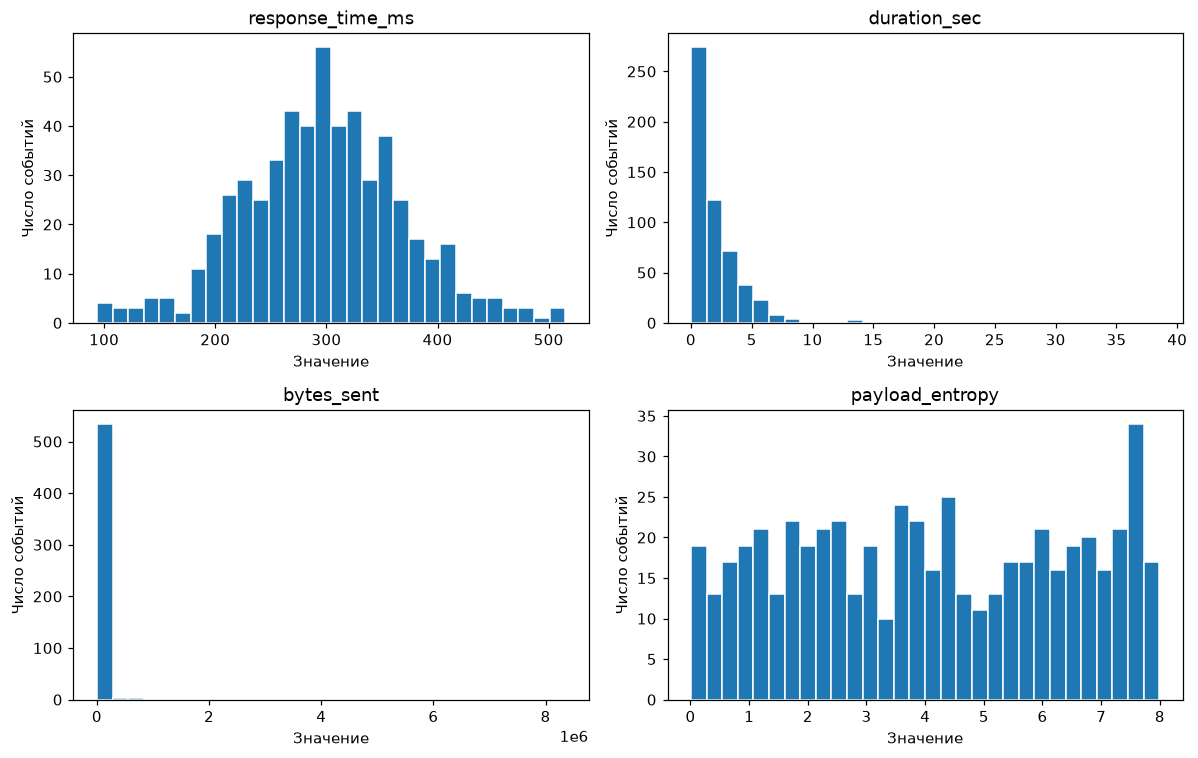

In [5]:
numeric = [
    'duration_sec', 'bytes_sent', 'n_packets', 'response_time_ms',
    'payload_entropy', 'failed_logins', 'auth_balance'
]

# IQR — расстояние между 75-м и 25-м процентилями.
summary = pd.DataFrame(index=numeric)
summary['Минимум'] = train[numeric].min()
summary['Максимум'] = train[numeric].max()
summary['Медиана'] = train[numeric].median()
summary['Стандартное отклонение'] = train[numeric].std()
summary['IQR'] = train[numeric].quantile(0.75) - train[numeric].quantile(0.25)
summary['Асимметрия'] = train[numeric].skew()
summary['Эксцесс'] = train[numeric].kurt()
display(summary.round(3))

# Четыре гистограммы помогают увидеть форму, которую таблица не показывает.
hist_columns = ['response_time_ms', 'duration_sec', 'bytes_sent', 'payload_entropy']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column in zip(axes.flat, hist_columns):
    ax.hist(train[column], bins=30, edgecolor='white')
    ax.set_title(column)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Число событий')
plt.tight_layout()
plt.show()

### Вывод по заданию 1

В обучающей выборке `response_time_ms` почти симметричен (асимметрия 0,028), а `payload_entropy` лежит между 0,007 и 7,989, близко к естественному диапазону 0–8 бит на байт. `bytes_sent` (асимметрия 13,135), `n_packets` (5,121), `failed_logins` (6,249) и `duration_sec` (5,878) имеют длинные правые хвосты; среднее и стандартное отклонение для них чувствительны к атакам. `auth_balance` достигает −69,342, поэтому к нему нельзя напрямую применять `log1p` или Box–Cox без изменения области определения. Порт 22 не «меньше» порта 443 по интенсивности атаки: `dst_port` обозначает сервис и не масштабируется как непрерывный признак.

## Задание 2. StandardScaler, RobustScaler и MinMaxScaler

Сравниваем масштабирование объёма трафика. `StandardScaler` вычитает среднее и делит на стандартное отклонение. `RobustScaler` опирается на медиану и IQR, поэтому его центр меньше зависит от больших выбросов. Линейное масштабирование меняет единицы измерения, но не исправляет асимметрию распределения.

In [8]:
# Каждый scaler получает только столбец train; test проходит лишь transform.
standard_bytes = StandardScaler()
robust_bytes = RobustScaler()

bytes_train_standard = standard_bytes.fit_transform(train[['bytes_sent']]).ravel()
bytes_test_standard = standard_bytes.transform(test[['bytes_sent']]).ravel()
bytes_train_robust = robust_bytes.fit_transform(train[['bytes_sent']]).ravel()
bytes_test_robust = robust_bytes.transform(test[['bytes_sent']]).ravel()

def describe_values(values):
    # Одинаковые показатели позволяют честно сравнить три шкалы.
    values = pd.Series(values)
    return {
        'Медиана': values.median(),
        'IQR': values.quantile(0.75) - values.quantile(0.25),
        '95-й процентиль': values.quantile(0.95),
        '99-й процентиль': values.quantile(0.99),
        'Максимум': values.max()
    }

scale_comparison = pd.DataFrame({
    'Исходный': describe_values(train['bytes_sent']),
    'StandardScaler': describe_values(bytes_train_standard),
    'RobustScaler': describe_values(bytes_train_robust)
}).T
display(scale_comparison.round(3))

# Смотрим, где находится обычный трафик относительно атак.
position = train[['attack_type', 'is_attack']].copy()
position['После StandardScaler'] = bytes_train_standard
position['После RobustScaler'] = bytes_train_robust
display(position.groupby('is_attack')[
    ['После StandardScaler', 'После RobustScaler']
].median().round(3))
display(position.groupby('attack_type')[
    ['После StandardScaler', 'После RobustScaler']
].median().round(3))

,Медиана,IQR,95-й процентиль,99-й процентиль,Максимум
Исходный,3602.465,13018.162,151915.832,1711739.633,8349956.410
StandardScaler,-0.143,0.028,0.181,3.587,18.079
RobustScaler,-0.000,1.000,11.393,131.212,641.131


,После StandardScaler,После RobustScaler
is_attack,,
0,-0.144,-0.048
1,-0.095,1.659


,После StandardScaler,После RobustScaler
attack_type,,
benign,-0.144,-0.048
bruteforce,-0.145,-0.085
ddos,0.417,19.704
exfiltration,0.068,7.402
port_scan,-0.146,-0.117


### Вывод по объёму трафика

Для `bytes_sent` после `StandardScaler` обучающий IQR составляет лишь 0,028, а медиана обычных событий равна −0,144: основная масса данных сжалась рядом с большими объёмами. После `RobustScaler` IQR равен 1, а медианы обычных и DDoS-событий составляют −0,048 и 19,704. Такой масштаб лучше сохраняет различия в основной массе при выбросах. Если распределение примерно симметрично и большие значения не определяют масштаб, подойдёт `StandardScaler`. Ни один линейный scaler не исправляет форму длинного хвоста; для этого полезно отдельно проверить `log1p`.

In [10]:
# Энтропия имеет физические границы около [0, 8], но scaler учится
# по фактическим минимуму и максимуму train, а не по числам 0 и 8.
entropy_scaler = MinMaxScaler()
entropy_train = entropy_scaler.fit_transform(train[['payload_entropy']]).ravel()
entropy_test = entropy_scaler.transform(test[['payload_entropy']]).ravel()

outside = int(((entropy_test < 0) | (entropy_test > 1)).sum())
print('Train после MinMax: минимум', round(entropy_train.min(), 4),
      'максимум', round(entropy_train.max(), 4))
print('Test после MinMax: минимум', round(entropy_test.min(), 4),
      'максимум', round(entropy_test.max(), 4))
print('Тестовых значений вне [0, 1]:', outside)

# Пример будущего допустимого значения 8.0: оно может быть выше max(train).
future_entropy = pd.DataFrame({'payload_entropy': [8.0]})
future_scaled = entropy_scaler.transform(future_entropy)[0, 0]
print('Если энтропия нового события равна 8.0, результат:', round(future_scaled, 4))

Train после MinMax: минимум 0.0 максимум 1.0
Test после MinMax: минимум 0.0007 максимум 0.998
Тестовых значений вне [0, 1]: 0
Если энтропия нового события равна 8.0, результат: 1.0013


### Вывод по энтропии

В данном `test` преобразованная энтропия находится между 0,0007 и 0,9980; за [0, 1] не вышло ни одно из 150 значений. Тем не менее допустимое новое значение энтропии 8,0 даёт 1,0013, поскольку максимум `train` равен 7,98949. Это нормальное поведение `MinMaxScaler` и не повод обучать его повторно на `test`. Для неизменной физической шкалы можно отдельно делить энтропию на 8; в задании проверяется именно поведение обученного `MinMaxScaler`.

## Задание 3. Разреженные признаки и нормализация строк

TF-IDF признаки часто равны нулю. `MaxAbsScaler` не вычитает среднее и сохраняет такие нули. `Normalizer` действует иначе: делит каждую строку на её L2-норму и оставляет только направление вектора.

In [13]:
sparse_cols = ['tfidf_error', 'tfidf_timeout', 'tfidf_admin']

# fit — только на train, transform — на train и test.
maxabs = MaxAbsScaler()
tfidf_train_scaled = maxabs.fit_transform(train[sparse_cols])
tfidf_test_scaled = maxabs.transform(test[sparse_cols])

zero_share = pd.DataFrame({
    'До': (train[sparse_cols] == 0).mean().to_numpy(),
    'После MaxAbs': (tfidf_train_scaled == 0).mean(axis=0)
}, index=sparse_cols)
display(zero_share.round(3))
print('Доля нулей во всей матрице до:', round((train[sparse_cols].to_numpy() == 0).mean(), 3))
print('Доля нулей во всей матрице после:', round((tfidf_train_scaled == 0).mean(), 3))

# Нормализатор не запоминает параметры; нулевой вектор остаётся нулевым.
l2_normalizer = Normalizer(norm='l2')
tfidf_train_l2 = l2_normalizer.transform(tfidf_train_scaled)
tfidf_test_l2 = l2_normalizer.transform(tfidf_test_scaled)
row_norms = np.linalg.norm(tfidf_train_l2, axis=1)
nonzero_norms = row_norms[row_norms > 0]
print('Ненулевых строк:', len(nonzero_norms), 'из', len(row_norms))
print('Минимальная и максимальная норма ненулевой строки:',
      round(nonzero_norms.min(), 6), round(nonzero_norms.max(), 6))

Доля нулей во всей матрице до: 0.849
Доля нулей во всей матрице после: 0.849
Ненулевых строк: 218 из 550
Минимальная и максимальная норма ненулевой строки: 1.0 1.0


,До,После MaxAbs
tfidf_error,0.815,0.815
tfidf_timeout,0.844,0.844
tfidf_admin,0.889,0.889


### Вывод по разреженности и L2-норме

Суммарная доля нулей в трёх TF‑IDF столбцах осталась 84,9% до и после `MaxAbsScaler`. Среди 550 обучающих событий 218 имеют ненулевой TF‑IDF профиль; L2-норма каждой такой строки после нормализации равна 1. Это полезно в UEBA, когда сравнивается состав действий пользователя, а не их общий объём. Для DDoS-детектора объём является ключевым сигналом: пропорциональные профили из 100 и 10 000 пакетов после нормализации имеют одинаковое направление. Поэтому признаки интенсивности нужно сохранять отдельно от нормализованного профиля.

## Задание 4. Нелинейные преобразования

Сравним формы распределений на `train`. `log1p(x)` и квадратный корень определены для неотрицательных чисел; Box–Cox требует строго положительных. `Yeo–Johnson` допускает отрицательные значения и подходит для `auth_balance`.

Lambda Box-Cox: -0.0627
Lambda Yeo-Johnson: 1.33


,Асимметрия,Эксцесс
bytes_sent исходный,13.135,208.729
bytes_sent log1p,0.449,0.545
bytes_sent sqrt,6.484,55.243
bytes_sent Box-Cox,-0.010,0.285
auth_balance исходный,-3.828,18.069
auth_balance Yeo-Johnson,0.004,1.886


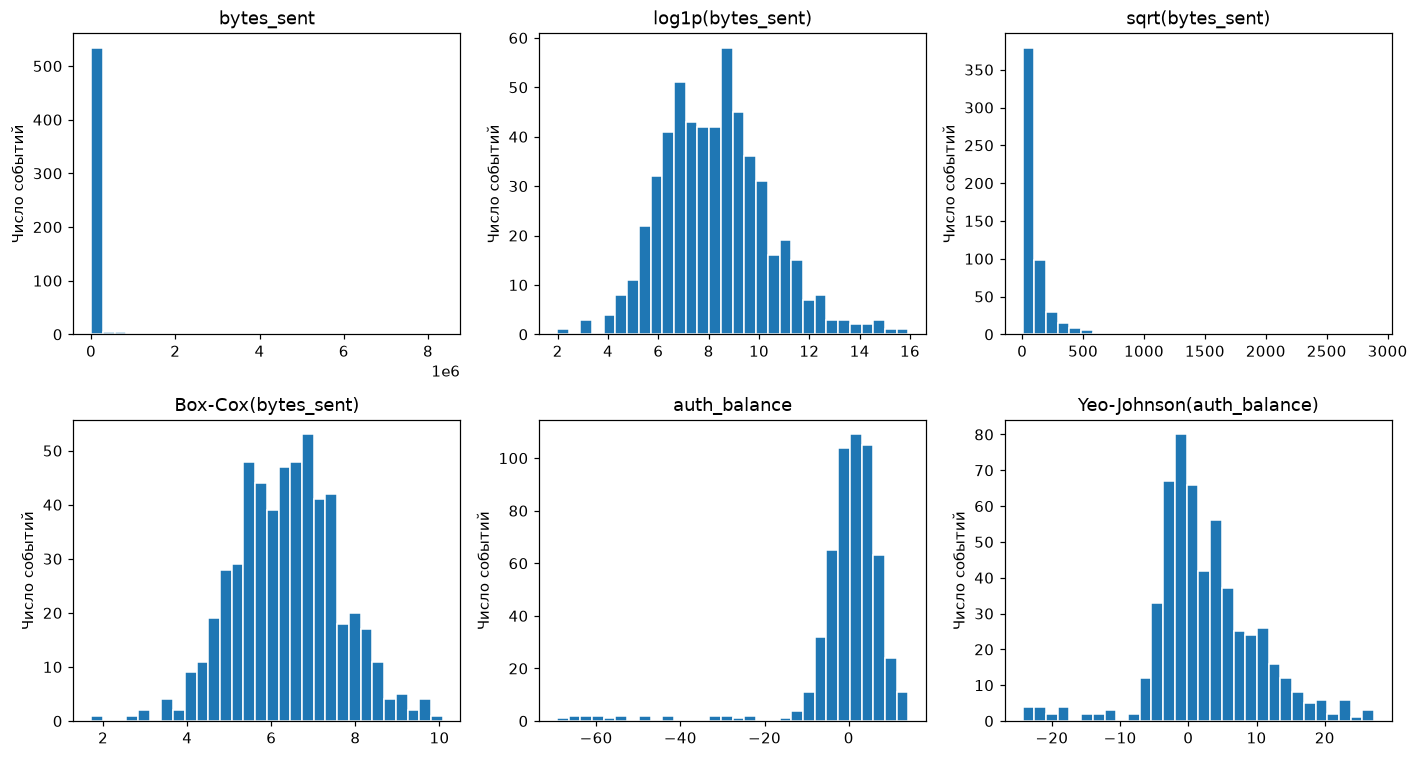

In [16]:
# Проверяем области определения до преобразований.
assert train['bytes_sent'].min() > 0, 'Box–Cox требует строго положительные значения'
assert train['auth_balance'].min() < 0, 'В этом задании auth_balance должен содержать отрицательные значения'

bytes_original = train['bytes_sent']
bytes_log = np.log1p(bytes_original)
bytes_sqrt = np.sqrt(bytes_original)

# PowerTransformer подбирает параметр lambda только на train.
boxcox = PowerTransformer(method='box-cox', standardize=False)
bytes_boxcox = boxcox.fit_transform(train[['bytes_sent']]).ravel()
bytes_boxcox_test = boxcox.transform(test[['bytes_sent']]).ravel()

yeojohnson = PowerTransformer(method='yeo-johnson', standardize=False)
balance_yj = yeojohnson.fit_transform(train[['auth_balance']]).ravel()
balance_yj_test = yeojohnson.transform(test[['auth_balance']]).ravel()

def shape_stats(values):
    # pandas.skew и kurt показывают асимметрию и избыточный эксцесс.
    values = pd.Series(values)
    return {'Асимметрия': values.skew(), 'Эксцесс': values.kurt()}

shape_table = pd.DataFrame({
    'bytes_sent исходный': shape_stats(bytes_original),
    'bytes_sent log1p': shape_stats(bytes_log),
    'bytes_sent sqrt': shape_stats(bytes_sqrt),
    'bytes_sent Box-Cox': shape_stats(bytes_boxcox),
    'auth_balance исходный': shape_stats(train['auth_balance']),
    'auth_balance Yeo-Johnson': shape_stats(balance_yj)
}).T
display(shape_table.round(3))
print('Lambda Box-Cox:', round(boxcox.lambdas_[0], 4))
print('Lambda Yeo-Johnson:', round(yeojohnson.lambdas_[0], 4))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
plots = [
    (bytes_original, 'bytes_sent'), (bytes_log, 'log1p(bytes_sent)'),
    (bytes_sqrt, 'sqrt(bytes_sent)'), (bytes_boxcox, 'Box-Cox(bytes_sent)'),
    (train['auth_balance'], 'auth_balance'), (balance_yj, 'Yeo-Johnson(auth_balance)')
]
for ax, (values, title) in zip(axes.flat, plots):
    ax.hist(values, bins=30, edgecolor='white')
    ax.set_title(title)
    ax.set_ylabel('Число событий')
plt.tight_layout()
plt.show()

### Вывод по нелинейным преобразованиям

Асимметрия `bytes_sent` снизилась с 13,135 до 0,449 после `log1p`, до 6,484 после квадратного корня и до −0,010 после Box–Cox. Для этого набора Box–Cox дал наиболее симметричную форму и эксцесс 0,285; его обученная степень λ = −0,0627. Box–Cox допустим здесь, потому что все обучающие значения строго больше нуля; к нулю и отрицательным числам его применять нельзя. Для `auth_balance` Yeo–Johnson снизил модуль асимметрии с 3,828 до 0,004 при λ = 1,3300, сохранив возможность работать с отрицательными значениями. Логарифмирование меняет форму распределения, но не устанавливает единый масштаб для разных признаков, поэтому перед Ridge его дополняют масштабированием. Параметры степенных преобразований из `train` без повторной подгонки применены к `test`.

## Задание 5. Безопасный конвейер и качество регрессии

Прогнозируем `severity_score` по семи числовым признакам. Базовый конвейер использует `StandardScaler` и Ridge. Второй сначала преобразует четыре скошенных признака, затем применяет `RobustScaler` и Ridge. `TransformedTargetRegressor` масштабирует целевой признак при обучении и автоматически возвращает прогноз в исходную шкалу.

In [19]:
features = [
    'bytes_sent', 'duration_sec', 'n_packets', 'response_time_ms',
    'payload_entropy', 'failed_logins', 'auth_balance'
]
X_train = train[features].copy()
X_test = test[features].copy()
y_train = train['severity_score'].copy()
y_test = test['severity_score'].copy()

# Pipeline вызывает fit для scaler только на X_train.
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])
baseline.fit(X_train, y_train)
prediction_baseline = baseline.predict(X_test)

def feature_engineering(data):
    # Создаём копию, чтобы исходная таблица осталась без изменений.
    changed = data.copy()
    changed['bytes_sent'] = np.log1p(changed['bytes_sent'])
    changed['duration_sec'] = 1 / (changed['duration_sec'] + 0.55)
    changed['n_packets'] = np.log1p(changed['n_packets'])
    changed['failed_logins'] = np.log1p(changed['failed_logins'])
    return changed

# FunctionTransformer помещает создание признаков внутрь конвейера.
improved_pipeline = Pipeline([
    ('features', FunctionTransformer(feature_engineering, validate=False)),
    ('scale', RobustScaler()),
    ('ridge', Ridge(alpha=1.0))
])

# Цель масштабируется только во время fit на y_train.
improved = TransformedTargetRegressor(
    regressor=improved_pipeline,
    transformer=StandardScaler()
)
improved.fit(X_train, y_train)
prediction_improved = improved.predict(X_test)

In [20]:
def model_metrics(actual, predicted):
    # MAE и RMSE измеряются в баллах severity_score.
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R²': r2_score(actual, predicted),
        'Мин. прогноз': np.min(predicted),
        'Макс. прогноз': np.max(predicted)
    }

quality = pd.DataFrame({
    'StandardScaler + Ridge': model_metrics(y_test, prediction_baseline),
    'Преобразования + RobustScaler + Ridge': model_metrics(y_test, prediction_improved)
}).T
display(quality.round(3))
print('Фактический диапазон severity_score на test:',
      round(y_test.min(), 3), '—', round(y_test.max(), 3))

# Выбираем меньшую MAE, если R² не стал заметно хуже.
best_name = quality['MAE'].idxmin()
print('Меньшая MAE у варианта:', best_name)

Фактический диапазон severity_score на test: 27.248 — 95.232
Меньшая MAE у варианта: Преобразования + RobustScaler + Ridge


,MAE,RMSE,R²,Мин. прогноз,Макс. прогноз
StandardScaler + Ridge,9.569,14.308,0.197,37.096,187.142
Преобразования + RobustScaler + Ridge,3.188,4.313,0.927,26.541,96.108


### Записка для SOC

На тестовых 150 событиях базовый конвейер дал MAE 9,569, RMSE 14,308 и R² 0,197. Вариант с `log1p` для объёма, пакетов и неудачных входов, обратной длительностью и `RobustScaler` дал MAE 3,188, RMSE 4,313 и R² 0,927, поэтому среди двух заданных вариантов выбран он. `TransformedTargetRegressor` вернул его прогнозы в исходные баллы `severity_score`: они лежат между 26,541 и 96,108. Базовая модель выдала максимум 187,142 балла, что выходит за естественную шкалу тяжести и требует отдельного контроля. Все параметры преобразований и регрессии обучены только на `train`; `test` использован лишь для сравнения. При применении в SOC стоит проверять стабильность метрик по времени и типам атак, а также отслеживать выход прогнозов за допустимый диапазон. Выбор гиперпараметров и дальнейшее сравнение моделей следует проводить на отдельной валидации, сохранив финальный тест нетронутым.